In [99]:
import torch
from torchvision import datasets, transforms
from copy import copy
from torch.utils.data import DataLoader, random_split, Subset
import psutil
import torch.nn.functional as F
import random
import matplotlib.pyplot  as plt
%matplotlib inline

device = 'cuda'
g = torch.Generator(device=device).manual_seed(42) # for reproducability

In [2]:
train_dataset = datasets.CIFAR10(
    root="../data_1",
    train=True,
    download=True,
    transform=transforms.ToTensor()
)

In [41]:
split_generator = torch.Generator().manual_seed(42)

train_subset, val_subset = random_split(
    train_dataset,
    [45000, 5000],
    generator=split_generator
)

train_loader = DataLoader(
    train_subset, batch_size=64, shuffle=True
)

val_loader = DataLoader(
    val_subset, batch_size=64, shuffle=False
)

In [100]:
augmented_dataset = copy(train_dataset)
augmented_dataset.transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
])

augmented_train_subset = Subset(
    augmented_dataset,
    train_subset.indices
)

augmented_train_loader = DataLoader(
    augmented_train_subset,
    batch_size=64,
    shuffle=True
)

In [ ]:
test_dataset = datasets.CIFAR10(
    root=train_dataset.root,
    train=False,               # Separate test split
    download=True,
    transform=transforms.ToTensor()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)

Test images: 10000
Test accuracy: 66.24%


In [32]:
class Conv2D:  
    def __init__(self, in_channels, out_channels, kernel_size, stride=1, padding=0):
        fan_in = in_channels*kernel_size*kernel_size
        self.weight = torch.randn((out_channels, in_channels, kernel_size, kernel_size), generator=g, device=device) * (2 / fan_in)**0.5
        self.bias = torch.zeros(out_channels, device=device)
        self.stride = stride
        self.padding = padding
        
        self.weight.requires_grad_(True)
        self.bias.requires_grad_(True)
    
    def __call__(self, x):
        k = self.weight.shape[2]

        patches = torch.nn.functional.unfold(
            x, kernel_size=k, padding=self.padding, stride=self.stride
        )
        weights_flat = self.weight.reshape(self.weight.shape[0], -1)

        out = weights_flat @ patches
        out = out + self.bias.reshape(1, -1, 1)
        
        height_out = (x.shape[2] + 2 * self.padding - k) // self.stride + 1
        width_out = (x.shape[3] + 2 * self.padding - k) // self.stride + 1

        self.out = out.reshape(
            x.shape[0], self.weight.shape[0], height_out, width_out
        )
        return self.out
    
    def parameters(self):
        return [self.weight] + [self.bias]
    
class MaxPool2D:
    def __init__(self, kernel_size=2, stride=2):
        self.kernel_size = kernel_size
        self.stride = stride

    def __call__(self,x):
        # (B, C * k * k, number_of_patches)
        patches = torch.nn.functional.unfold(
            x, kernel_size=self.kernel_size, stride=self.stride
        )
        
        B, C, H, W = x.shape
        k = self.kernel_size

        patches = patches.reshape(B, C, k * k, -1)
        
        out = patches.max(dim=2).values
        
        height_out = (H - k) // self.stride + 1
        width_out = (W - k) // self.stride + 1

        self.out = out.reshape(B, C, height_out, width_out)
        return self.out

    def parameters(self):
        return []

class Flatten:
    def __call__(self, x):
        self.out = x.reshape(x.shape[0], -1)
        return self.out

    def parameters(self):
        return []

class Linear:
    
    def __init__(self, fan_in, fan_out, bias=True):
        self.weight = torch.randn((fan_in, fan_out), generator=g, device=device)  *  (2 / fan_in)**0.5
        self.bias = torch.zeros(fan_out, device=device) if bias else None
        
        self.weight.requires_grad_(True)

        if self.bias is not None:
            self.bias.requires_grad_(True)
    
    def __call__(self, x):
        self.out = x @ self.weight
        if self.bias is not None:
            self.out += self.bias
        return self.out
    
    def parameters(self):
        return [self.weight] + ([] if self.bias is None else [self.bias])
    
class ReLU:
    def __call__(self, x):
        self.out = torch.clamp(x, min=0)
        return self.out
    
    def parameters(self):
        return []

In [36]:
class Sequential:
    def __init__(self, layers):
        self.layers = layers
    
    def __call__(self, x):
        for layer in self.layers:
            x = layer(x)
        return x
    
    def train(self):
        for layer in self.layers:
            if hasattr(layer, "training"):
                layer.training = True
    
    def eval(self):
        for layer in self.layers:
            if hasattr(layer, "training"):
                layer.training = False
    
    def parameters(self):
        return [p for layer in self.layers for p in layer.parameters()]

In [6]:
# conv = Conv2D(1, 1, 2)

# with torch.no_grad():
#     conv.weight.copy_(torch.tensor(
#         [[[[1., 0.],
#            [0., -1.]]]], device=device
#     ))
#     conv.bias.fill_(2.)

# x_test = torch.tensor(
#     [[[[1., 2., 3.],
#        [4., 5., 6.],
#        [7., 8., 9.]]]], device=device
# )

# out = conv(x_test)
# print(out)
# print(out.shape)

out.sum().backward()
print(conv.bias.grad)

tensor([4.], device='cuda:0')


In [7]:
print(conv.weight.grad)
print(conv.bias.grad)

tensor([[[[12., 16.],
          [24., 28.]]]], device='cuda:0')
tensor([4.], device='cuda:0')


In [19]:
conv_stride = Conv2D(1, 1, 3, stride=2)
x_test = torch.randn((1, 1, 5, 5), generator=g, device=device)

print(conv_stride(x_test).shape)

torch.Size([1, 1, 2, 2])


In [22]:
conv_pad = Conv2D(1, 1, 3, stride=1, padding=1)
x_test = torch.randn((1, 1, 5, 5), generator=g, device=device)

print(conv_pad(x_test).shape)

torch.Size([1, 1, 5, 5])


In [23]:
x_small = torch.arange(
    1, 10, dtype=torch.float32, device=device
).reshape(1, 1, 3, 3)

patches = torch.nn.functional.unfold(x_small, kernel_size=2)

print(x_small)
print(patches)
print(patches.shape)

tensor([[[[1., 2., 3.],
          [4., 5., 6.],
          [7., 8., 9.]]]], device='cuda:0')
tensor([[[1., 2., 4., 5.],
         [2., 3., 5., 6.],
         [4., 5., 7., 8.],
         [5., 6., 8., 9.]]], device='cuda:0')
torch.Size([1, 4, 4])


In [27]:
conv_pad = Conv2D(1, 1, 3, stride=1, padding=1)
x_test = torch.randn((1, 1, 5, 5), generator=g, device=device)

print(conv_pad(x_test).shape)

torch.Size([1, 1, 5, 5])


In [28]:
conv = Conv2D(1, 1, 2)

with torch.no_grad():
    conv.weight.copy_(torch.tensor(
        [[[[1., 0.],
           [0., -1.]]]], device=device
    ))
    conv.bias.fill_(2.)

x_test = torch.arange(
    1, 10, dtype=torch.float32, device=device
).reshape(1, 1, 3, 3)

out = conv(x_test)
print(out)

out.sum().backward()
print(conv.weight.grad)
print(conv.bias.grad)

tensor([[[[-2., -2.],
          [-2., -2.]]]], device='cuda:0', grad_fn=<ViewBackward0>)
tensor([[[[12., 16.],
          [24., 28.]]]], device='cuda:0')
tensor([4.], device='cuda:0')


In [31]:
pool = MaxPool2D(kernel_size=2, stride=2)

x_test = torch.tensor(
    [[[[1., 5.],
       [3., 2.]]]],
    device=device,
    requires_grad=True
)

out = pool(x_test)
print(out)

out.sum().backward()
print(x_test.grad)

tensor([[[[5.]]]], device='cuda:0', grad_fn=<ViewBackward0>)
tensor([[[[0., 1.],
          [0., 0.]]]], device='cuda:0')


In [ ]:
layers = [
    Conv2D(3, 8, 3, padding=1),
    ReLU(),
    MaxPool2D(kernel_size=2, stride=2),
    Conv2D(8, 16, 3, padding=1),
    ReLU(),
    MaxPool2D(kernel_size=2, stride=2),
    Flatten(),
    Linear(2048, 10)
]

In [ ]:
model = Sequential(layers)

learning_rate = 0.001
parameters = model.parameters()
first_moments = [torch.zeros_like(p) for p in parameters]
second_moments = [torch.zeros_like(p) for p in parameters]
t = 0

In [34]:
x = torch.randn((2, 3, 32, 32), generator=g, device=device)

for layer in layers:
    x = layer(x)
    print(type(layer).__name__, x.shape)

Conv2D torch.Size([2, 8, 32, 32])
ReLU torch.Size([2, 8, 32, 32])
MaxPool2D torch.Size([2, 8, 16, 16])
Flatten torch.Size([2, 2048])
Linear torch.Size([2, 10])


In [39]:
parameters = [p for layer in layers for p in layer.parameters()]

for p in parameters:
    p.requires_grad_(True)

print(sum(p.numel() for p in parameters))

20714


In [53]:
## WITH ADAM
def train_one_epoch(model, loader, learning_rate,first_moments, second_moments, t):
    
    model.train()
    parameters = model.parameters()
    
    for i, (images, labels) in enumerate(loader):
        
        images = images.to(device)
        labels = labels.to(device)
        
        logits = model(images)
        loss = F.cross_entropy(logits, labels)

        for p in parameters:
            p.grad = None
            
        loss.backward()
    
        with torch.no_grad():
            t+=1
            for p, m ,s in zip(parameters, first_moments, second_moments):
                m.mul_(0.9).add_(0.1 * p.grad)
                s.mul_(0.999).add_(0.001 * p.grad**2)
                
                m_hat = m/(1-0.9**t)
                s_hat = s / (1 - 0.999**t)

                update = m_hat / (s_hat.sqrt() + 1e-8)
                p -= learning_rate * update
            
        # if i %100 == 0:
        #     print(i, loss.item())
    return t

In [49]:
learning_rate = 0.001

for epoch in range(3, 6):
    t = train_one_epoch(
        model, train_loader, learning_rate,
        first_moments, second_moments, t
    )

    train_acc = evaluate(model, train_loader)
    val_acc = evaluate(model, val_loader)

    print(
        f"Epoch {epoch} | "
        f"Train: {train_acc:.2f}% | Validation: {val_acc:.2f}%"
    )

Epoch 3 | Train: 54.35% | Validation: 49.86%
Epoch 4 | Train: 55.80% | Validation: 50.84%
Epoch 5 | Train: 56.71% | Validation: 51.56%


In [46]:
def evaluate(model, loader):
    
    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            logits = model(images)

            predictions = logits.argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.shape[0]

    return 100 * correct / total

In [47]:
print(f"Train accuracy: {evaluate(model, train_loader):.2f}%")
print(f"Validation accuracy: {evaluate(model, val_loader):.2f}%")

Train accuracy: 44.34%
Validation accuracy: 42.48%


In [89]:
layers2 = [
    Conv2D(3, 8, 3, padding=1),
    ReLU(),
    MaxPool2D(kernel_size=2, stride=2),
    Conv2D(8, 16, 3, padding=1),
    ReLU(),
    MaxPool2D(kernel_size=2, stride=2),
    Flatten(),
    Linear(1024, 10)
]

In [90]:
model2 = Sequential(layers2)

parameters2 = model2.parameters()
for p in parameters2:
    p.requires_grad_(True)

first_moments2 = [torch.zeros_like(p) for p in parameters2]
second_moments2 = [torch.zeros_like(p) for p in parameters2]
t2 = 0

In [91]:
learning_rate2 = 0.001

for epoch in range(1, 11):
    t2 = train_one_epoch(
        model2, train_loader, learning_rate2,
        first_moments2, second_moments2, t2
    )

    train_acc = evaluate(model2, train_loader)
    val_acc = evaluate(model2, val_loader)

    print(
        f"Epoch {epoch} | "
        f"Train: {train_acc:.2f}% | Validation: {val_acc:.2f}%"
    )

Epoch 1 | Train: 50.29% | Validation: 48.70%
Epoch 2 | Train: 56.47% | Validation: 54.18%
Epoch 3 | Train: 58.29% | Validation: 55.24%
Epoch 4 | Train: 60.15% | Validation: 57.28%
Epoch 5 | Train: 60.93% | Validation: 58.06%
Epoch 6 | Train: 62.99% | Validation: 59.16%
Epoch 7 | Train: 63.27% | Validation: 59.82%
Epoch 8 | Train: 62.96% | Validation: 59.98%
Epoch 9 | Train: 65.12% | Validation: 61.56%
Epoch 10 | Train: 66.05% | Validation: 61.32%


In [101]:
model_aug = Sequential([
    Conv2D(3, 8, 3, padding=1),
    ReLU(),
    MaxPool2D(2, 2),
    Conv2D(8, 16, 3, padding=1),
    ReLU(),
    MaxPool2D(2, 2),
    Flatten(),
    Linear(1024, 10)
])

parameters_aug = model_aug.parameters()
for p in parameters_aug:
    p.requires_grad_(True)

first_moments_aug = [torch.zeros_like(p) for p in parameters_aug]
second_moments_aug = [torch.zeros_like(p) for p in parameters_aug]
t_aug = 0

In [102]:
for epoch in range(1, 11):
    t_aug = train_one_epoch(
        model_aug, augmented_train_loader, 0.001,
        first_moments_aug, second_moments_aug, t_aug
    )

    train_acc = evaluate(model_aug, train_loader)
    val_acc = evaluate(model_aug, val_loader)

    print(
        f"Epoch {epoch} | "
        f"Train: {train_acc:.2f}% | Validation: {val_acc:.2f}%"
    )

Epoch 1 | Train: 52.79% | Validation: 52.24%
Epoch 2 | Train: 55.48% | Validation: 54.84%
Epoch 3 | Train: 57.95% | Validation: 56.60%
Epoch 4 | Train: 59.08% | Validation: 56.66%
Epoch 5 | Train: 59.74% | Validation: 57.98%
Epoch 6 | Train: 62.08% | Validation: 59.66%
Epoch 7 | Train: 62.73% | Validation: 60.72%
Epoch 8 | Train: 62.47% | Validation: 60.50%
Epoch 9 | Train: 64.43% | Validation: 62.12%
Epoch 10 | Train: 64.31% | Validation: 61.78%


In [103]:
best_val = evaluate(model_aug, val_loader)
best_weights = [p.detach().clone() for p in parameters_aug]
best_epoch = 10
epochs_without_improvement = 0

for epoch in range(11, 51):
    t_aug = train_one_epoch(
        model_aug, augmented_train_loader, 0.001,
        first_moments_aug, second_moments_aug, t_aug
    )

    train_acc = evaluate(model_aug, train_loader)
    val_acc = evaluate(model_aug, val_loader)

    print(
        f"Epoch {epoch} | "
        f"Train: {train_acc:.2f}% | Validation: {val_acc:.2f}%"
    )

    if val_acc > best_val:
        best_val = val_acc
        best_epoch = epoch
        best_weights = [p.detach().clone() for p in parameters_aug]
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= 7:
        print("Stopping: no validation improvement for 7 epochs.")
        break

# Restore the best weights saved during this continuation
with torch.no_grad():
    for p, saved in zip(parameters_aug, best_weights):
        p.copy_(saved)

print(f"Restored epoch {best_epoch}: validation {best_val:.2f}%")

Epoch 11 | Train: 64.57% | Validation: 61.88%
Epoch 12 | Train: 64.51% | Validation: 61.14%
Epoch 13 | Train: 64.29% | Validation: 61.30%
Epoch 14 | Train: 65.04% | Validation: 62.04%
Epoch 15 | Train: 65.39% | Validation: 62.86%
Epoch 16 | Train: 66.55% | Validation: 63.38%
Epoch 17 | Train: 66.20% | Validation: 62.94%
Epoch 18 | Train: 66.06% | Validation: 62.70%
Epoch 19 | Train: 66.92% | Validation: 63.70%
Epoch 20 | Train: 67.36% | Validation: 63.86%
Epoch 21 | Train: 66.40% | Validation: 62.96%
Epoch 22 | Train: 67.10% | Validation: 64.32%
Epoch 23 | Train: 67.31% | Validation: 63.74%
Epoch 24 | Train: 66.94% | Validation: 63.42%
Epoch 25 | Train: 67.51% | Validation: 63.58%
Epoch 26 | Train: 66.97% | Validation: 64.10%
Epoch 27 | Train: 68.36% | Validation: 64.72%
Epoch 28 | Train: 68.23% | Validation: 64.42%
Epoch 29 | Train: 67.81% | Validation: 64.74%
Epoch 30 | Train: 69.23% | Validation: 64.98%
Epoch 31 | Train: 68.60% | Validation: 64.50%
Epoch 32 | Train: 67.99% | Validat

In [92]:
confusion = torch.zeros(10, 10, dtype=torch.int64)

In [94]:
def get_confusion_matrix(model, loader):
    model.eval()
    confusion = torch.zeros(10, 10, dtype=torch.int64)

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            logits = model(images)
            predictions = logits.argmax(dim=1)

            for actual, predicted in zip(labels.cpu(), predictions.cpu()):
                confusion[actual.item(), predicted.item()] += 1

    return confusion


confusion = get_confusion_matrix(model2, val_loader)
print(confusion)

tensor([[341,  26,  21,  14,   5,   3,   2,   4,  50,  22],
        [ 10, 433,   4,   8,   0,   2,   2,   1,  18,  34],
        [ 43,  12, 250,  45,  63,  27,  34,  20,  31,   7],
        [ 11,  14,  28, 231,  39,  61,  35,  15,  26,  11],
        [ 20,   9,  50,  49, 247,   9,  38,  27,  14,   8],
        [  6,  10,  43, 139,  30, 230,  17,  25,  10,   4],
        [  4,  14,  25,  45,  48,   8, 340,   5,   9,   9],
        [ 10,  13,  19,  47,  51,  33,   5, 297,   5,  20],
        [ 52,  29,   5,  10,   2,   1,   3,   1, 391,  10],
        [ 17, 111,   5,  13,   3,   4,   5,   4,  33, 306]])


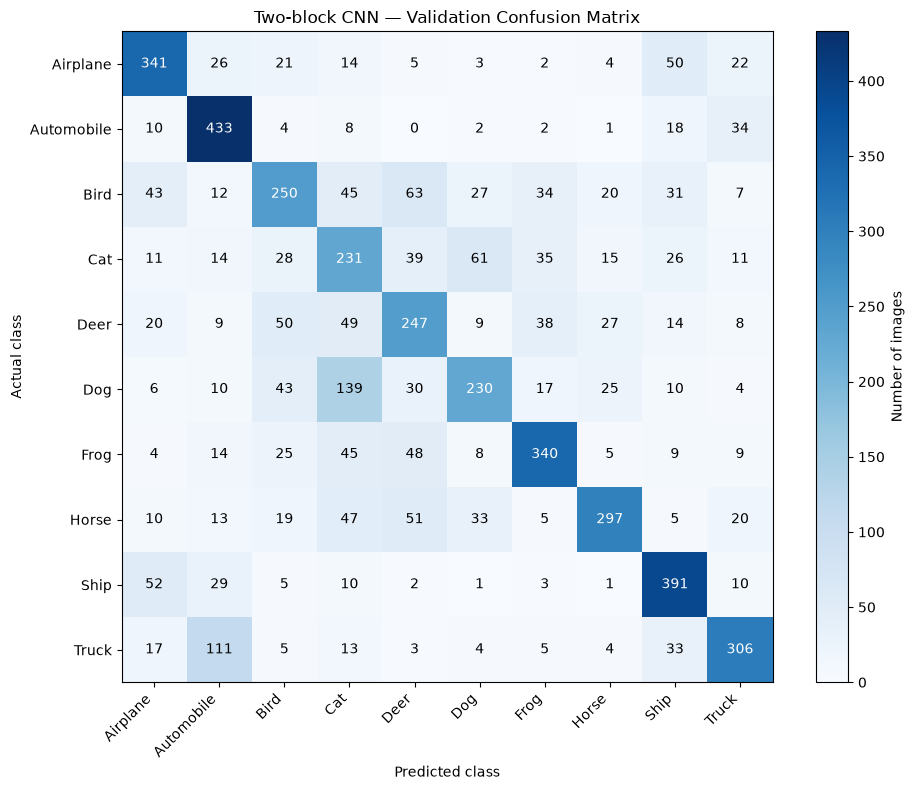

In [ ]:
import matplotlib.pyplot as plt

classes = [
    "Airplane", "Automobile", "Bird", "Cat", "Deer",
    "Dog", "Frog", "Horse", "Ship", "Truck"
]

cm = confusion.cpu().numpy()

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(cm, cmap="Blues")
fig.colorbar(im, ax=ax, label="Number of images")

ax.set(
    xticks=range(10),
    yticks=range(10),
    xticklabels=classes,
    yticklabels=classes,
    xlabel="Predicted class",
    ylabel="Actual class",
    title="Two-block CNN — Validation Confusion Matrix"
)
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")

for row in range(10):
    for col in range(10):
        ax.text(
            col, row, str(cm[row, col]),
            ha="center", va="center",
            color="white" if cm[row, col] > cm.max() / 2 else "black"
        )

plt.tight_layout()
plt.show()

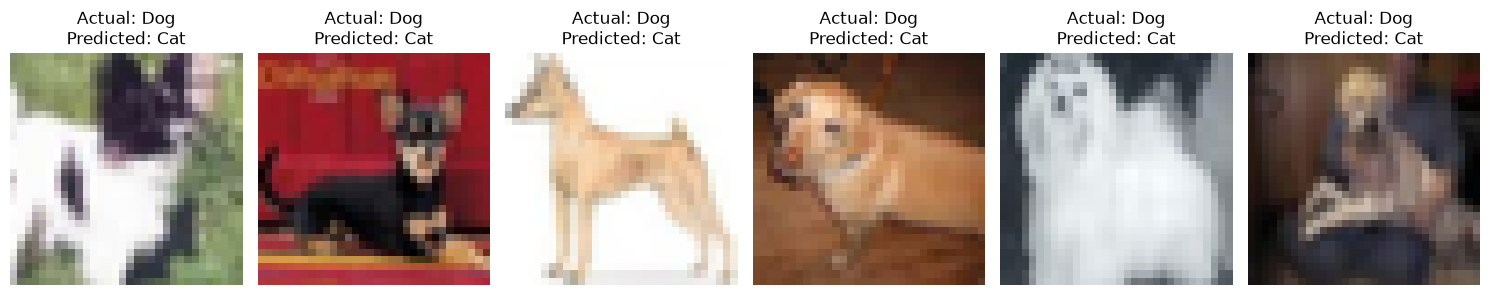

In [98]:
mistakes = []
model2.eval()

with torch.no_grad():
    for images, labels in val_loader:
        predictions = model2(images.to(device)).argmax(dim=1).cpu()
        mask = (labels.cpu() == 5) & (predictions == 3)

        for img in images.cpu()[mask]:
            mistakes.append(img)
            if len(mistakes) == 6:
                break

        if len(mistakes) == 6:
            break

if mistakes:
    fig, axes = plt.subplots(1, len(mistakes), figsize=(15, 3), squeeze=False)

    for ax, img in zip(axes[0], mistakes):
        ax.imshow(img.permute(1, 2, 0))
        ax.set_title("Actual: Dog\nPredicted: Cat")
        ax.axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("No dog → cat mistakes found.")

In [105]:
print(f"Test images: {len(test_dataset)}")
print(f"Test accuracy: {evaluate(model_aug, test_loader):.2f}%")

Test images: 10000
Test accuracy: 66.24%


In [106]:
torch.save(
    {
        "parameters": [
            p.detach().cpu().clone()
            for p in model_aug.parameters()
        ],
        "epoch": 47,
        "validation_accuracy": 66.50,
        "test_accuracy": 66.24,
    },
    "cnn_aug_best.pt"
)

print("Saved: cnn_aug_best.pt")

Saved: cnn_aug_best.pt
